In [69]:

import os
import random
import requests
from typing import Annotated
from typing_extensions import TypedDict
from dotenv import load_dotenv
from IPython.display import Image, display
import gradio as gr
from langchain_groq import ChatGroq
from langchain_community.tools import GoogleSerperRun
from langchain_community.utilities import GoogleSerperAPIWrapper
from langchain_core.tools import tool
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode, tools_condition
from langgraph.checkpoint.memory import MemorySaver
from langgraph.checkpoint.sqlite import SqliteSaver

load_dotenv(override=True)

True

In [70]:
class State(TypedDict):
    messages: Annotated[list, add_messages]

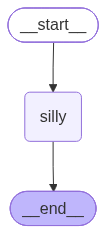

In [71]:
nouns = ["Cabbages", "Unicorns", "Toasters", "Penguins", "Bananas", "Eels", "Pickles"]
adjectives = ["outrageous", "smelly", "pedantic", "existential", "sparkly", "haunted"]

def silly_node(state: State) -> dict:
    sentence = f"{random.choice(nouns)} are {random.choice(adjectives)}"
    return {"messages": [{"role": "assistant", "content": sentence}]}

builder = StateGraph(State)
builder.add_node("silly", silly_node)
builder.add_edge(START, "silly")
builder.add_edge("silly", END)
graph = builder.compile()

display(Image(graph.get_graph().draw_mermaid_png()))

In [72]:
result = graph.invoke({"messages": [{"role": "user", "content": "say something"}]})
print(result["messages"][-1].content)

Cabbages are pedantic


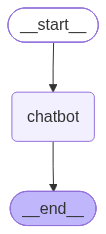

In [73]:
llm = ChatGroq(model="openai/gpt-oss-120b")

def chatbot_node(state: State) -> dict:
    return {"messages": [llm.invoke(state["messages"])]}

builder = StateGraph(State)
builder.add_node("chatbot", chatbot_node)
builder.add_edge(START, "chatbot")
builder.add_edge("chatbot", END)
graph = builder.compile()

display(Image(graph.get_graph().draw_mermaid_png()))

In [74]:
result = graph.invoke({"messages": [{"role": "user", "content": "who is the winner of ipl 2026?"}]})
print(result["messages"][-1].content)

I’m sorry, but I don’t have information about events that took place after my knowledge cutoff in June 2024, so I don’t know which team won the IPL in 2026.


In [75]:
search = GoogleSerperRun(api_wrapper=GoogleSerperAPIWrapper())

@tool
def send_push_notification(text: str) -> str:
    """Send a short push notification to the user's phone."""
    requests.post(
        "https://api.pushover.net/1/messages.json",
        data={"token": os.getenv("PUSHOVER_TOKEN"), "user": os.getenv("PUSHOVER_USER"), "message": text},
    )
    return "Notification sent"

tools = [search, send_push_notification]
llm_with_tools = llm.bind_tools(tools)

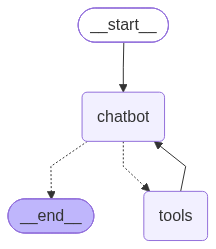

In [76]:
def chatbot_node(state: State) -> dict:
    return {"messages": [llm_with_tools.invoke(state["messages"])]}

builder = StateGraph(State)

builder.add_node("chatbot", chatbot_node)
builder.add_node("tools", ToolNode(tools))

builder.add_edge(START, "chatbot")
builder.add_conditional_edges("chatbot", tools_condition)
builder.add_edge("tools", "chatbot")

graph = builder.compile()

display(Image(graph.get_graph().draw_mermaid_png()))

In [77]:
result = graph.invoke({"messages": [{"role": "user", "content": "Use your search tool to tell me the who is the winner of ipl 2026 and send me a push notification."}]})
print(result["messages"][-1].content)

The winner of the 2026 Indian Premier League (IPL) was **Royal Challengers Bengaluru (RCB)**, who defeated the Gujarat Titans in the final. A push notification confirming this has also been sent to your device.


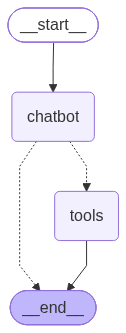

In [103]:
class State(TypedDict):
    messages: Annotated[list, add_messages]
    tamil: str

def translator_node(state: State) -> dict:
    last = state["messages"][-1].content
    prompt = f"Translate this into Tamil, replying with the translation only:\n\n{last}"
    return {"tamil": llm.invoke(prompt).content}

builder = StateGraph(State)

builder.add_node("chatbot", chatbot_node)
builder.add_node("tools", ToolNode(tools))

builder.add_edge(START, "chatbot")
builder.add_conditional_edges("chatbot", tools_condition)
builder.add_edge("chatbot", END)
graph = builder.compile()

display(Image(graph.get_graph().draw_mermaid_png()))

In [105]:
result = graph.invoke({"messages": [{"role": "user", "content": "In one sentence, explain about greyrock method in human psychology?"}]})
print(result["messages"][-1].content)


The grey‑rock method is a psychological tactic in which a person deliberately becomes bland, unresponsive, and emotionally neutral to make themselves uninteresting and thereby discourage a manipulative or abusive individual from seeking their attention or control.


In [106]:
memory = MemorySaver()

builder = StateGraph(State)
builder.add_node("chatbot", chatbot_node)
builder.add_node("tools", ToolNode(tools))
builder.add_node("translator", translator_node)
builder.add_edge(START, "chatbot")
builder.add_conditional_edges("chatbot", tools_condition)
graph = builder.compile(checkpointer=memory)


config = {"configurable": {"thread_id": "conversation-1"}}
graph.invoke({"messages": [{"role": "user", "content": "Hi, my name is loki."}]}, config)
second = graph.invoke({"messages": [{"role": "user", "content": "What is my name?"}]}, config)
print(second["messages"][-1].content)

Your name is Loki. How can I help you today?


In [107]:
with SqliteSaver.from_conn_string("memory.db") as sql_memory:
    durable_graph = builder.compile(checkpointer=sql_memory)
    sql_config = {"configurable": {"thread_id": "conversation-2"}}
    durable_graph.invoke({"messages": [{"role": "user", "content": "Remember that my favorite cricket player is virat kohli."}]}, sql_config)
    reply = durable_graph.invoke({"messages": [{"role": "user", "content": "What is my favorite cricketer?"}]}, sql_config)
    print(reply["messages"][-1].content)


Your favorite cricketer is Virat Kohli.


In [108]:
snapshot = graph.get_state(config)
messages = snapshot.values["messages"]
print("Messages stored so far:", len(messages))

for message in messages:
    print(message.content)

history = list(graph.get_state_history(config))
print("Number of saved checkpoints:", len(history))


Messages stored so far: 4
Hi, my name is loki.
Nice to meet you, Loki! How can I assist you today?
What is my name?
Your name is Loki. How can I help you today?
Number of saved checkpoints: 6


In [109]:
for h in reversed(history):            # history is newest first; reversed reads as a story
      m = h.metadata
      queued = ", ".join(t.name for t in h.tasks) or "(run complete)"
      print(f"step {m['step']:>2}  {m['source']:<5}  messages={len(h.values.get('messages', []))}  about to run: {queued}")

step -1  input  messages=0  about to run: __start__
step  0  loop   messages=1  about to run: chatbot
step  1  loop   messages=2  about to run: (run complete)
step  2  input  messages=2  about to run: __start__
step  3  loop   messages=3  about to run: chatbot
step  4  loop   messages=4  about to run: (run complete)


In [110]:
# Time travel: take a checkpoint from earlier and resume the graph from that exact moment
earlier = history[len(history) // 2]
print("A checkpoint from earlier held", len(earlier.values["messages"]), "messages")

replay_config = {"configurable": {"thread_id": "conversation-1",
                                  "checkpoint_id": earlier.config["configurable"]["checkpoint_id"]}}
resumed = graph.invoke(None, replay_config)
print("Resumed from the past; the graph now holds", len(resumed["messages"]), "messages")

again = graph.invoke({"messages": [{"role": "user", "content": "What do you know about me?"}]}, replay_config)
print(again["messages"][-1].content)


A checkpoint from earlier held 2 messages
Resumed from the past; the graph now holds 2 messages
I only know what you’ve shared with me so far—your name, Loki. If there’s anything specific you’d like me to remember or any details you’d like to tell me about yourself, just let me know!


In [ ]:
def chat(user_input: str, history):
    config = {"configurable": {"thread_id": "gradio-session4"}}
    result = graph.invoke({"messages": [{"role": "user", "content": user_input}]}, config)
    return f"{result['messages'][-1].content}*"

gr.ChatInterface(chat).launch()

* Running on local URL:  http://127.0.0.1:7864
* To create a public link, set `share=True` in `launch()`.


Traceback (most recent call last):
  File "/home/loki/code/AI engineering/langgraph_practice/.venv/lib/python3.12/site-packages/gradio/queueing.py", line 867, in process_events
    response = await route_utils.call_process_api(
               ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/home/loki/code/AI engineering/langgraph_practice/.venv/lib/python3.12/site-packages/gradio/route_utils.py", line 393, in call_process_api
    output = await app.get_blocks().process_api(
             ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/home/loki/code/AI engineering/langgraph_practice/.venv/lib/python3.12/site-packages/gradio/blocks.py", line 2280, in process_api
    result = await self.call_function(
             ^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/home/loki/code/AI engineering/langgraph_practice/.venv/lib/python3.12/site-packages/gradio/blocks.py", line 1655, in call_function
    prediction = await fn(*processed_input)
                 ^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/home/loki/code/AI engin